## LNER Character-Span Fine-Tuning — v3

This revision fixes a label-provenance bug in candidate generation, scores spans using both the matching label’s boundary confidence and span-classifier probability, trains on boundary-generated hard negatives, and uses Fold-1-derived label-specific maximum span lengths. It retains the custom Phase 1 decoder and full fine-tuning.

# Phase 2 LNER — Character-Boundary-Aware Span Model (v2)

This revision keeps the custom Phase 1 legal decoder and pretrained checkpoint, and addresses three failure modes seen in the first span-model run: document-wide top-boundary pruning, endpoint-only span features, and unweighted span-class imbalance. It adds raw candidate-pair recall diagnostics on Fold 2.

Run from the top in a fresh Kaggle session. This notebook has been syntax-checked and synthetic-tested, but has not been trained end-to-end on Kaggle.

## Key v2 changes

1. Candidate boundaries are selected per overlapping character chunk, rather than only 40 start/end positions per label over an entire long document.
2. Span classification now incorporates the mean representation of the span's interior as well as its endpoints and length.
3. The span loss uses softened inverse-frequency weights based on Fold 1 labels, and uses fewer NONE negatives per positive.
4. Fold 2 reports raw candidate-pair recall overall and per label before confidence thresholding/decoding. A low value means candidate generation is still the bottleneck; high candidate recall with low F1 points to classification or decoding.

This is a controlled next experiment, not a guaranteed score increase. Inspect the candidate recall output before deciding what to tune next.

In [22]:
# ============================================================
# 1. Setup and input assets
# ============================================================
import os
import json
import random
import math
from pathlib import Path

import torch
import torch.nn as nn
import torch.nn.functional as F
from huggingface_hub import hf_hub_download
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

# Phase 1 model configuration — must match the checkpoint architecture.
VOCAB_SIZE = 32000
N_EMBD = 512
N_LAYER = 15
N_HEAD = 8
N_KV_HEAD = 4
MODEL_CONTEXT_LENGTH = 2048

# Change these only if your Kaggle input files use different names.
BPE_FILENAME = "custom_bpe_scratch.json"
MODEL_FILENAME = "pytorch_model.bin"

def find_input_file(filename):
    """Find an exact filename anywhere under /kaggle/input."""
    roots = [Path("/kaggle/input"), Path.cwd()]
    for root in roots:
        if not root.exists():
            continue
        direct = root / filename
        if direct.is_file():
            return str(direct)
        try:
            for candidate in root.rglob(filename):
                if candidate.is_file():
                    return str(candidate)
        except (PermissionError, OSError):
            pass
    raise FileNotFoundError(
        f"Could not find {filename}. Attach it as a Kaggle input, "
        "or update BPE_FILENAME / MODEL_FILENAME in this cell."
    )

BPE_PATH = find_input_file(BPE_FILENAME)
MODEL_PATH = find_input_file(MODEL_FILENAME)
print("BPE tokenizer:", BPE_PATH)
print("Pretrained model:", MODEL_PATH)

# HF_TOKEN is optional for a public dataset. If the repository is private,
# add a Kaggle secret named HF containing a Hugging Face access token.
try:
    from kaggle_secrets import UserSecretsClient
    HF_TOKEN = UserSecretsClient().get_secret("HF")
except Exception:
    HF_TOKEN = os.environ.get("HF_TOKEN")

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"


Device: cuda
CUDA available: True
BPE tokenizer: /kaggle/input/datasets/baihuwang07/phase1/custom_bpe_scratch.json
Pretrained model: /kaggle/input/datasets/baihuwang07/phase1/pytorch_model.bin


## 2. Load the custom BPE tokenizer


In [23]:
# ============================================================
# 2. Load the custom byte-level BPE tokenizer
# ============================================================
class CustomByteLevelBPE:
    def __init__(self, vocab_size=32000):
        self.vocab_size = vocab_size
        self.merges = {} 
        
        # Base vocabulary of all 256 individual bytes
        self.vocab = {i: bytes([i]) for i in range(256)}
        self.inverse_vocab = {bytes([i]): i for i in range(256)}
        self.next_id = 256
        
        # Reserved Special Tokens
        self.pad_id = 0  

    def train(self, texts, target_vocab_size):
        print("Aggregating byte sequence frequencies...")
        word_freqs = Counter()
        
        # 1. Chunk texts to prevent massive contiguous memory blocks
        for text in texts:
            # Split into words and whitespace blocks to keep sequence lengths small
            chunks = re.findall(r'\S+|\s+', text)
            for chunk in chunks:
                word_freqs[chunk.encode("utf-8")] += 1
                
        # 2. Drop singletons to massively save RAM
        word_freqs = {w: f for w, f in word_freqs.items() if f > 1}
        print(f"Unique byte sequences to process: {len(word_freqs):,}")

        # Initialize splits: word -> list of byte integers
        splits = {word: list(word) for word in word_freqs}
        
        # 3. Build fast inverted index
        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)
        
        for word, freq in word_freqs.items():
            split = splits[word]
            for j in range(len(split) - 1):
                pair = (split[j], split[j+1])
                pair_counts[pair] += freq
                pair_to_words[pair].add(word)

        num_merges = target_vocab_size - 256
        print(f"Starting {num_merges} merges...")
        
        for i in range(num_merges):
            if not pair_counts:
                break
                
            best_pair = max(pair_counts, key=pair_counts.get)
            new_id = self.next_id
            
            # Record the merge
            self.merges[best_pair] = new_id
            self.vocab[new_id] = self.vocab[best_pair[0]] + self.vocab[best_pair[1]]
            self.inverse_vocab[self.vocab[new_id]] = new_id
            
            # 4. FAST INCREMENTAL UPDATE: Only process words containing the best_pair
            words_to_update = list(pair_to_words.get(best_pair, []))
            
            del pair_counts[best_pair]
            if best_pair in pair_to_words:
                del pair_to_words[best_pair]
            
            for word in words_to_update:
                split = splits[word]
                freq = word_freqs[word]
                
                # Remove old pairs associated with this word from global tracking
                for j in range(len(split) - 1):
                    pair = (split[j], split[j+1])
                    if pair != best_pair:
                        pair_counts[pair] -= freq
                        if pair_counts[pair] <= 0:
                            del pair_counts[pair]
                        if word in pair_to_words.get(pair, set()):
                            pair_to_words[pair].remove(word)

                # Execute the merge on this word's internal list
                new_split = []
                j = 0
                while j < len(split):
                    if j < len(split) - 1 and (split[j], split[j+1]) == best_pair:
                        new_split.append(new_id)
                        j += 2
                    else:
                        new_split.append(split[j])
                        j += 1
                splits[word] = new_split

                # Add newly formed pairs back to global tracking
                for j in range(len(new_split) - 1):
                    pair = (new_split[j], new_split[j+1])
                    pair_counts[pair] += freq
                    pair_to_words[pair].add(word)
                    
            self.next_id += 1
            
            if (i + 1) % 1000 == 0:
                print(f"Merge {i + 1}/{num_merges} completed.")
                
        print("BPE Training complete!")

    def _get_stats(self, ids):
        counts = Counter()
        for i in range(len(ids) - 1):
            counts[(ids[i], ids[i+1])] += 1
        return counts

    def _merge_vocab(self, ids, pair, idx):
        newids = []
        i = 0
        while i < len(ids):
            if i < len(ids) - 1 and ids[i] == pair[0] and ids[i+1] == pair[1]:
                newids.append(idx)
                i += 2
            else:
                newids.append(ids[i])
                i += 1
        return newids

    def encode(self, text):
        # Chunk text during encoding to prevent \(O(N^2)\) slowdowns on long documents
        chunks = re.findall(r'\S+|\s+', text)
        final_ids = []
        
        for chunk in chunks:
            ids = list(chunk.encode("utf-8"))
            while len(ids) >= 2:
                stats = self._get_stats(ids)
                pair = min(stats.keys(), key=lambda p: self.merges.get(p, float("inf")))
                if pair not in self.merges:
                    break 
                ids = self._merge_vocab(ids, pair, self.merges[pair])
            final_ids.extend(ids)
            
        return final_ids

    def decode(self, ids):
        b_text = b"".join(self.vocab[idx] for idx in ids if idx != self.pad_id)
        return b_text.decode("utf-8", errors="replace")

    def get_vocab_size(self):
        return len(self.vocab)

    def save(self, path):
        serializable_merges = {f"{p[0]},{p[1]}": v for p, v in self.merges.items()}
        serializable_vocab = {k: list(v) for k, v in self.vocab.items()}
        data = {
            "vocab_size": self.vocab_size,
            "next_id": self.next_id,
            "merges": serializable_merges,
            "vocab": serializable_vocab
        }
        with open(path, "w", encoding="utf-8") as f:
            json.dump(data, f, ensure_ascii=False)

    def load(self, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
            
        self.vocab_size = data["vocab_size"]
        self.next_id = data["next_id"]
        self.merges = {tuple(map(int, k.split(","))): v for k, v in data["merges"].items()}
        self.vocab = {int(k): bytes(v) for k, v in data["vocab"].items()}
        self.inverse_vocab = {v: k for k, v in self.vocab.items()}

tokenizer = CustomByteLevelBPE(vocab_size=VOCAB_SIZE)
tokenizer.load(BPE_PATH)
print(f"Loaded BPE vocabulary: {tokenizer.get_vocab_size():,} tokens")


Loaded BPE vocabulary: 32,000 tokens


## 3. Define the Phase 1 model architecture


In [24]:
# ============================================================
# 3. Define the Phase 1 model architecture
# ============================================================
import math
class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight

def precompute_freqs_cis(dim, end, theta=10000.0):
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2)[: (dim // 2)].float() / dim))
    t = torch.arange(end, device=freqs.device)
    freqs_cis = torch.polar(torch.ones_like(torch.outer(t, freqs).float()), torch.outer(t, freqs).float())
    return torch.view_as_real(freqs_cis)

def apply_rotary_emb(xq, xk, freqs_cis):
    xq_ = torch.view_as_complex(xq.float().reshape(*xq.shape[:-1], -1, 2))
    xk_ = torch.view_as_complex(xk.float().reshape(*xk.shape[:-1], -1, 2))
    freqs_cis = freqs_cis.view(1, xq_.shape[1], 1, xq_.shape[-1])
    return torch.view_as_real(xq_ * freqs_cis).flatten(3).type_as(xq), torch.view_as_real(xk_ * freqs_cis).flatten(3).type_as(xk)

class ManualTransformerAttention(nn.Module):
    def __init__(self, head_dim):
        super().__init__()
        self.scale = 1.0 / math.sqrt(head_dim)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor, is_causal: bool = True, attention_mask=None):
        B, H, L_q, D = q.shape
        _, _, L_k, _ = k.shape
        
        k_transposed = k.transpose(-2, -1).contiguous()
        scores = torch.matmul(q, k_transposed) * self.scale
        
        if is_causal and L_q > 1:
            mask = torch.tril(torch.ones(L_q, L_k, device=q.device)).view(1, 1, L_q, L_k)
            scores = scores.masked_fill(mask == 0, float('-inf'))

        # Apply padding mask for batched inference
        if attention_mask is not None:
            pad_mask = attention_mask.view(attention_mask.size(0), 1, 1, attention_mask.size(1))
            scores = scores.masked_fill(pad_mask == 0, float('-inf'))
            
        weights = torch.softmax(scores, dim=-1)
        return torch.matmul(weights, v.contiguous())

class GroupedQueryAttention(nn.Module):
    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        self.n_heads, self.n_kv_heads, self.head_dim = n_heads, n_kv_heads, dim // n_heads
        
        self.wq = nn.Linear(dim, n_heads * self.head_dim, bias=False)
        self.wk = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wv = nn.Linear(dim, n_kv_heads * self.head_dim, bias=False)
        self.wo = nn.Linear(dim, dim, bias=False)
        
        # QK-Norm layers for stabilization
        self.q_norm = RMSNorm(n_heads * self.head_dim)
        self.k_norm = RMSNorm(n_kv_heads * self.head_dim)
        
        self.manual_attention = ManualTransformerAttention(self.head_dim)

    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        B, L, _ = x.shape
        
        # Apply QK-Norm directly after linear projections
        q = self.q_norm(self.wq(x)).view(B, L, self.n_heads, self.head_dim)
        k = self.k_norm(self.wk(x)).view(B, L, self.n_kv_heads, self.head_dim)
        v = self.wv(x).view(B, L, self.n_kv_heads, self.head_dim)
        
        q, k = apply_rotary_emb(q, k, freqs_cis)
        
        if kv_cache is not None:
            k_cache, v_cache = kv_cache
            k = torch.cat([k_cache, k], dim=1) 
            v = torch.cat([v_cache, v], dim=1)
        new_kv_cache = (k, v)

        k_rep = k.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        v_rep = v.repeat_interleave(self.n_heads // self.n_kv_heads, dim=2)
        
        out = self.manual_attention(
            q=q.transpose(1, 2), 
            k=k_rep.transpose(1, 2), 
            v=v_rep.transpose(1, 2), 
            is_causal=(L > 1),
            attention_mask=attention_mask
        )
        
        out = out.transpose(1, 2).contiguous().view(B, L, -1)
        return self.wo(out), new_kv_cache

class CustomTransformerBlock(nn.Module):
    def __init__(self, dim, n_heads, n_kv_heads):
        super().__init__()
        # Restored separate norm layers for sequential architecture
        self.norm1 = RMSNorm(dim)
        self.norm2 = RMSNorm(dim)
        self.attn = GroupedQueryAttention(dim, n_heads, n_kv_heads)
        
        # Standard Sequential FFN with SiLU (Swish) instead of GELU
        self.ffn = nn.Sequential(
            nn.Linear(dim, dim * 4, bias=False), 
            nn.SiLU(), 
            nn.Linear(dim * 4, dim, bias=False)
        )
        
    def forward(self, x, freqs_cis, kv_cache=None, attention_mask=None):
        # Sequential Residual Architecture
        attn_out, new_kv_cache = self.attn(self.norm1(x), freqs_cis, kv_cache, attention_mask=attention_mask)
        h = x + attn_out
        
        out = h + self.ffn(self.norm2(h))
        
        return out, new_kv_cache

class CustomLegalModel(nn.Module):
    def __init__(self, vocab_size, dim, n_layers, n_heads, n_kv_heads, max_seq_len):
        super().__init__()
        self.tok_embeddings = nn.Embedding(vocab_size, dim)
        self.layers = nn.ModuleList([CustomTransformerBlock(dim, n_heads, n_kv_heads) for _ in range(n_layers)])
        self.norm = RMSNorm(dim)
        self.output = nn.Linear(dim, vocab_size, bias=False)
        self.output.weight = self.tok_embeddings.weight
        
        self.register_buffer("freqs_cis", precompute_freqs_cis(dim // n_heads, max_seq_len))

    def forward(self, tokens, start_pos=0, kv_caches=None, attention_mask=None):
        B, L = tokens.shape
        freqs_cis = self.freqs_cis[start_pos : start_pos + L].to(tokens.device)
        freqs_cis = torch.view_as_complex(freqs_cis)
        
        h = self.tok_embeddings(tokens)
        new_caches = []
        
        for i, layer in enumerate(self.layers):
            cache_i = kv_caches[i] if kv_caches is not None else None
            h, new_cache = layer(h, freqs_cis, kv_cache=cache_i, attention_mask=attention_mask)
            new_caches.append(new_cache)
            
        return self.output(self.norm(h)), new_caches



## 4. Load the Phase 1 checkpoint


In [25]:
# ============================================================
# 4. Load pretrained model weights
# ============================================================
model = CustomLegalModel(
    VOCAB_SIZE,
    N_EMBD,
    N_LAYER,
    N_HEAD,
    N_KV_HEAD,
    MODEL_CONTEXT_LENGTH,
).to(DEVICE)

checkpoint = torch.load(MODEL_PATH, map_location="cpu", weights_only=True)
# Accept either a plain state_dict or common checkpoint wrappers.
if isinstance(checkpoint, dict):
    for key in ("model_state_dict", "state_dict", "model"):
        if key in checkpoint and isinstance(checkpoint[key], dict):
            checkpoint = checkpoint[key]
            break

# Remove a DataParallel prefix if the weights were saved from multiple GPUs.
state_dict = {
    key.removeprefix("module."): value
    for key, value in checkpoint.items()
    if isinstance(value, torch.Tensor)
}
missing, unexpected = model.load_state_dict(state_dict, strict=False)
if missing or unexpected:
    raise RuntimeError(
        "Checkpoint does not exactly match the Phase 1 architecture.\n"
        f"Missing keys (first 10): {missing[:10]}\n"
        f"Unexpected keys (first 10): {unexpected[:10]}"
    )

model.eval()
print(f"Loaded pretrained decoder ({sum(p.numel() for p in model.parameters()):,} parameters).")


Loaded pretrained decoder (59,665,152 parameters).


## 5. Download Phase 2 data and train the character-span model

This section downloads the capstone Fold 1/Fold 2/Fold 3 files, verifies the character offsets, builds overlapping context windows, and constructs character-boundary and candidate-span targets. The decoder is initialized from the supplied Phase 1 checkpoint and remains fully trainable.

In [26]:
# Phase 2 LNER experiment: full decoder fine-tuning + character-boundary span head
# The custom Phase 1 tokenizer and pretrained decoder are retained.

import json
import math
import numpy as np
import os
import re
import zipfile
from pathlib import Path
from collections import defaultdict

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

# -----------------------------
# Experiment settings
# -----------------------------
LNER_MAX_LEN = 768              # reduce to 512 if GPU memory is tight
LNER_WINDOW_STRIDE = 576        # overlap windows to reduce context-edge errors
LNER_BATCH_SIZE = 1             # safe starting point for full fine-tuning
LNER_GRAD_ACCUM_STEPS = 8       # effective batch size 8 windows
LNER_EPOCHS = 12                # early stopping controls overfitting
LNER_BACKBONE_LR = 3e-6         # conservative LR for pretrained decoder
LNER_HEAD_LR = 3e-5              # character/span head learns faster
LNER_WEIGHT_DECAY = 0.01
LNER_PATIENCE = 4
LNER_CLASS_WEIGHT_POWER = 0.25  # mild inverse-frequency weighting; avoid extreme rare-label boosts
LNER_LABEL_SMOOTHING = 0.0
LNER_SEED = 42
LNER_NUM_WORKERS = 0

random_seed = LNER_SEED
import random
random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(random_seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# -----------------------------
# Download Phase 2 dataset from Hugging Face (no Phase 2 dataset files needed in Kaggle input)
# -----------------------------
from huggingface_hub import hf_hub_download

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
HF_DATASET_SUBDIR = "Phase_2_LNER"

def download_phase2_file(filename, split_folder):
    repo_filename = f"{HF_DATASET_SUBDIR}/{split_folder}/{filename}"
    print(f"Downloading {repo_filename} from {HF_DATASET_REPO} ...")
    return hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=repo_filename,
        repo_type="dataset",
        token=HF_TOKEN or None,
    )

FOLD1_TEXT_PATH = download_phase2_file("fold1-text.json", "Train")
FOLD1_GOLD_PATH = download_phase2_file("fold1-gold.json", "Train")
FOLD2_TEXT_PATH = download_phase2_file("fold2-text.json", "Train")
FOLD2_GOLD_PATH = download_phase2_file("fold2-gold.json", "Train")
LABELS_PATH = download_phase2_file("labels.txt", "Train")
FOLD3_TEXT_PATH = download_phase2_file("fold3-text.json", "Test")

print("Phase 2 dataset files downloaded:")
for _path in (FOLD1_TEXT_PATH, FOLD1_GOLD_PATH, FOLD2_TEXT_PATH,
              FOLD2_GOLD_PATH, LABELS_PATH, FOLD3_TEXT_PATH):
    print("  ", _path)

# -----------------------------
# Read Phase 2 JSON formats
# -----------------------------
def read_json_or_jsonl(path):
    with open(path, "r", encoding="utf-8") as f:
        raw = f.read()
    try:
        return json.loads(raw)
    except json.JSONDecodeError:
        rows = []
        for line_no, line in enumerate(raw.splitlines(), 1):
            line = line.strip().rstrip(",")
            if not line:
                continue
            try:
                rows.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise ValueError(f"Invalid JSON in {path}, line {line_no}") from exc
        return rows


def _first_present(record, keys, default=None):
    for key in keys:
        if key in record:
            return record[key]
    return default


def normalise_documents(raw):
    """Return {str(document_id): document_text}; supports the stated ID -> text layout."""
    if isinstance(raw, dict):
        for container_key in ("documents", "data", "docs", "items"):
            if container_key in raw and isinstance(raw[container_key], (dict, list)):
                return normalise_documents(raw[container_key])
        docs = {}
        for key, value in raw.items():
            if isinstance(value, str):
                docs[str(key)] = value
            elif isinstance(value, dict):
                text = _first_present(value, ("text", "document", "content", "document_text"))
                doc_id = _first_present(value, ("id", "doc_id", "document_id", "docid"), key)
                if isinstance(text, str):
                    docs[str(doc_id)] = text
        if not docs:
            raise ValueError("Could not find document text. Expected a document-ID-to-text JSON object or records with id/text fields.")
        return docs
    if isinstance(raw, list):
        docs = {}
        for row in raw:
            if not isinstance(row, dict):
                continue
            doc_id = _first_present(row, ("id", "doc_id", "document_id", "docid", "documentId"))
            text = _first_present(row, ("text", "document", "content", "document_text"))
            if doc_id is not None and isinstance(text, str):
                docs[str(doc_id)] = text
        if not docs:
            raise ValueError("Could not find document ID/text records in the JSON list.")
        return docs
    raise ValueError(f"Unsupported document JSON root type: {type(raw).__name__}")


def normalise_entity(entity):
    """
    Accept both common annotation encodings:
      {"start": 1, "end": 5, "label": "COURT", "text": "..."}
      [1, 5, "COURT"] or [1, 5, "COURT", "..."]
    Offsets use end-exclusive character indexing.
    """
    if isinstance(entity, (list, tuple)):
        if len(entity) < 3:
            return None
        start, end, label = entity[:3]
        text = entity[3] if len(entity) > 3 else ""
    elif isinstance(entity, dict):
        start = _first_present(entity, ("start", "start_offset", "start_char", "start_character", "begin"))
        end = _first_present(entity, ("end", "end_offset", "end_char", "end_character", "stop"))
        label = _first_present(entity, ("label", "entity_label", "entity_type", "type"))
        text = _first_present(entity, ("text", "entity_text", "surface"), "")
    else:
        return None

    if start is None or end is None or label is None:
        return None
    try:
        start, end = int(start), int(end)
    except (TypeError, ValueError):
        return None
    if end <= start:
        return None
    return {"start": start, "end": end, "label": str(label).strip(), "text": str(text)}


def normalise_gold(raw):
    """Return {str(document_id): [normalized entity dicts]} for document-keyed or record-list JSON."""
    if isinstance(raw, dict):
        for container_key in ("annotations", "entities_by_document", "data", "documents", "records"):
            if container_key in raw and isinstance(raw[container_key], (dict, list)):
                return normalise_gold(raw[container_key])
        out = {}
        for doc_id, value in raw.items():
            if isinstance(value, list):
                ents = [normalise_entity(e) for e in value]
            elif isinstance(value, dict):
                embedded = _first_present(value, ("entities", "annotations", "spans"))
                if isinstance(embedded, list):
                    ents = [normalise_entity(e) for e in embedded]
                elif _first_present(value, ("start", "start_offset", "start_char")) is not None:
                    ent = normalise_entity(value)
                    record_id = _first_present(value, ("doc_id", "document_id", "docid", "id"), doc_id)
                    out.setdefault(str(record_id), [])
                    if ent is not None:
                        out[str(record_id)].append(ent)
                    continue
                else:
                    continue
            else:
                continue
            out[str(doc_id)] = [e for e in ents if e is not None]
        if not out:
            raise ValueError("Could not parse gold annotations. Expected a document-ID-to-entity-list mapping.")
        return out
    if isinstance(raw, list):
        out = defaultdict(list)
        for row in raw:
            if not isinstance(row, dict):
                continue
            doc_id = _first_present(row, ("doc_id", "document_id", "docid", "documentId", "id"))
            embedded = _first_present(row, ("entities", "annotations", "spans"))
            if doc_id is not None and isinstance(embedded, list):
                out[str(doc_id)].extend(e for e in (normalise_entity(x) for x in embedded) if e is not None)
                continue
            ent = normalise_entity(row)
            if doc_id is not None and ent is not None:
                out[str(doc_id)].append(ent)
        if not out:
            raise ValueError("Could not parse gold records from JSON list.")
        return dict(out)
    raise ValueError(f"Unsupported gold JSON root type: {type(raw).__name__}")


fold1_docs = normalise_documents(read_json_or_jsonl(FOLD1_TEXT_PATH))
fold1_gold = normalise_gold(read_json_or_jsonl(FOLD1_GOLD_PATH))
fold2_docs = normalise_documents(read_json_or_jsonl(FOLD2_TEXT_PATH))
fold2_gold = normalise_gold(read_json_or_jsonl(FOLD2_GOLD_PATH))
test_docs = normalise_documents(read_json_or_jsonl(FOLD3_TEXT_PATH))
with open(LABELS_PATH, "r", encoding="utf-8") as f:
    ENTITY_LABELS = [line.strip() for line in f if line.strip()]
# Handle a leading UTF-8 BOM and duplicate blank/duplicate label lines defensively.
ENTITY_LABELS = list(dict.fromkeys(label.lstrip("\ufeff").strip() for label in ENTITY_LABELS if label.strip()))
if not ENTITY_LABELS:
    raise ValueError("labels.txt is empty; cannot construct the entity classifier.")

print(f"Fold 1: {len(fold1_docs)} documents; {sum(len(fold1_gold.get(k, [])) for k in fold1_docs)} entities")
print(f"Fold 2: {len(fold2_docs)} documents; {sum(len(fold2_gold.get(k, [])) for k in fold2_docs)} entities")
print(f"Test:   {len(test_docs)} documents")

print("Entity labels:", ENTITY_LABELS)

def audit_phase2_data(documents, gold_by_doc, split_name):
    doc_ids = set(map(str, documents.keys()))
    gold_ids = set(map(str, gold_by_doc.keys()))
    matched_ids = doc_ids & gold_ids
    total_entities = sum(len(gold_by_doc.get(doc_id, [])) for doc_id in doc_ids)
    print(
        f"[{split_name} audit] docs={len(doc_ids):,}; gold-doc IDs={len(gold_ids):,}; "
        f"ID overlap={len(matched_ids):,}; gold entities={total_entities:,}"
    )
    if not documents:
        raise ValueError(f"{split_name}: no documents were loaded.")
    if not gold_by_doc:
        raise ValueError(
            f"{split_name}: no gold annotation records were parsed. "
            "Inspect the raw fold*-gold.json schema."
        )
    if total_entities == 0:
        # Show a raw annotation example to make schema mismatches obvious.
        sample_id = next(iter(gold_by_doc), None)
        sample_value = gold_by_doc.get(sample_id) if sample_id is not None else None
        raise ValueError(
            f"{split_name}: zero entities were parsed. This would inevitably produce 0 F1. "
            f"Example parsed gold for ID {sample_id!r}: {sample_value!r}. "
            "Expected each span to be [start, end, label] or a dict with start/end/label fields."
        )
    if not matched_ids:
        raise ValueError(
            f"{split_name}: document IDs in text and gold do not overlap. "
            f"Example text IDs: {list(doc_ids)[:3]}; gold IDs: {list(gold_ids)[:3]}"
        )
    bad_labels = sorted({
        str(ent.get("label"))
        for doc_id in matched_ids
        for ent in gold_by_doc.get(doc_id, [])
        if str(ent.get("label")) not in ENTITY_LABELS
    })
    if bad_labels:
        raise ValueError(
            f"{split_name}: annotation labels are not present in labels.txt: {bad_labels}. "
            f"Official labels: {ENTITY_LABELS}"
        )
    print(f"[{split_name} audit] sample gold: {next(iter(gold_by_doc.items()))[1][:3]}")

audit_phase2_data(fold1_docs, fold1_gold, "Fold 1")
audit_phase2_data(fold2_docs, fold2_gold, "Fold 2")

# -----------------------------
# Custom byte-level BPE encoder with character offsets
# -----------------------------
def encode_with_character_offsets(tokenizer, text, verify_parity=False):
    """Mirror CustomByteLevelBPE.encode() exactly while tracking Unicode character spans.

    The Phase 1 tokenizer is byte-level. Each UTF-8 byte initially maps to the Unicode
    character that generated it; merged byte tokens combine those spans. End offsets are
    exclusive, matching the Phase 2 character-span annotation convention.
    """
    all_ids, all_offsets = [], []
    if not text:
        return all_ids, all_offsets

    for match in re.finditer(r"\S+|\s+", text):
        chunk = match.group(0)
        ids = list(chunk.encode("utf-8"))
        spans = []
        absolute_char = match.start()
        for local_char, ch in enumerate(chunk):
            char_span = (absolute_char + local_char, absolute_char + local_char + 1)
            spans.extend([char_span] * len(ch.encode("utf-8")))

        # Same greedy merge priority as CustomByteLevelBPE.encode(): lowest merge ID first.
        while len(ids) >= 2:
            eligible = []
            for i in range(len(ids) - 1):
                pair = (ids[i], ids[i + 1])
                if pair in tokenizer.merges:
                    eligible.append((tokenizer.merges[pair], i, pair))
            if not eligible:
                break
            merge_id, _, pair = min(eligible, key=lambda x: (x[0], x[1]))

            new_ids, new_spans = [], []
            i = 0
            while i < len(ids):
                if i < len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
                    new_ids.append(merge_id)
                    new_spans.append((spans[i][0], max(spans[i][1], spans[i + 1][1])))
                    i += 2
                else:
                    new_ids.append(ids[i])
                    new_spans.append(spans[i])
                    i += 1
            ids, spans = new_ids, new_spans

        all_ids.extend(ids)
        all_offsets.extend(spans)

    # Optional parity check against the notebook's original tokenizer implementation.
    # Run this on a representative document once; repeating it for every document doubles
    # the tokenizer work and can be costly for a custom BPE implementation.
    if verify_parity:
        original_ids = tokenizer.encode(text)
        if all_ids != original_ids:
            raise RuntimeError(
                "Offset-aware BPE differs from tokenizer.encode() for this text. "
                "Check the custom tokenizer's merge implementation before training."
            )
    return all_ids, all_offsets


# One-time parity check: avoid running the original tokenizer a second time for every document.
_parity_sample = next(iter(fold1_docs.values()), "")
if _parity_sample:
    _parity_ids, _parity_offsets = encode_with_character_offsets(tokenizer, _parity_sample, verify_parity=True)
    assert len(_parity_ids) == len(_parity_offsets)
    print("Offset-aware BPE parity check passed on one fold-1 document.")


# -----------------------------
# Alignment coverage audit: catch tokenizer/character-offset issues before training
# -----------------------------
def audit_entity_alignment(documents, gold_by_doc, max_documents=200):
    total = 0
    exactly_representable = 0
    per_label = defaultdict(lambda: [0, 0])  # [representable, total]
    for doc_id, text in list(documents.items())[:max_documents]:
        entities = gold_by_doc.get(str(doc_id), [])
        if not entities:
            continue
        _, offsets = encode_with_character_offsets(tokenizer, text)
        token_starts = {a for a, _ in offsets}
        token_ends = {b for _, b in offsets}
        for entity in entities:
            start, end, label = entity["start"], entity["end"], entity["label"]
            total += 1
            per_label[label][1] += 1
            # This tokenizer covers the source string in order, so exact start/end token
            # boundaries are the key representability test.
            exact = start in token_starts and end in token_ends and end > start
            if exact:
                exactly_representable += 1
                per_label[label][0] += 1
    coverage = exactly_representable / max(1, total)
    print(f"Gold-span exact BPE boundary coverage in audit sample: {exactly_representable}/{total} = {coverage:.1%}")
    for label, (ok, n) in sorted(per_label.items()):
        print(f"  {label:16s} {ok:5d}/{n:<5d} ({ok/max(1,n):.1%})")
    if total and coverage < 0.50:
        print(
            "WARNING: Many gold spans do not align to exact BPE token boundaries. "
            "A BIO token head may be unable to reproduce their character spans exactly; "
            "consider a span-classification head or a tokenizer-aware boundary strategy."
        )

# -----------------------------
# -----------------------------
# Character-boundary-aware span model
# -----------------------------
# No BIO tags are produced. Every output span is represented directly with
# Python character offsets [start, end), including boundaries inside a BPE token.

IGNORE_INDEX = -100
LNER_MAX_SPAN_CHARS = 512
LNER_NEGATIVES_PER_POSITIVE = 4       # reduce NONE-class dominance during span training
LNER_MIN_NEGATIVES_PER_WINDOW = 32
LNER_MAX_NEGATIVES_PER_WINDOW = 128
TOP_BOUNDARIES_PER_LABEL = 64          # retained from the latest experiment; candidates remain label-specific
SPAN_DECODE_CHUNK_CHARS = 4096         # local candidate generation matches window-scale training
SPAN_DECODE_CHUNK_STRIDE = 3072        # 1024-char overlap; greater than the max span length
BOUNDARY_POS_WEIGHT_VALUE = 30.0
SPAN_CONFIDENCE_THRESHOLDS = [0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.65, 0.70]

# This diagnostic is retained to quantify the old BIO constraint. The span
# model itself does not require exact BPE boundary alignment.
audit_entity_alignment(fold1_docs, fold1_gold)
audit_entity_alignment(fold2_docs, fold2_gold)

LABEL_TO_ID = {label: i for i, label in enumerate(ENTITY_LABELS)}
ID_TO_LABEL = {i: label for label, i in LABEL_TO_ID.items()}
NUM_ENTITY_LABELS = len(ENTITY_LABELS)
PAD_ID = int(getattr(tokenizer, "pad_id", 0))

# Defensive validation: this task currently assumes non-overlapping gold spans.
def checked_entities(entities, text_length, doc_id="?"):
    out = []
    for ent in entities:
        s, e, label = int(ent["start"]), int(ent["end"]), str(ent["label"])
        if label not in LABEL_TO_ID:
            raise ValueError(f"Unknown entity label {label!r} in document {doc_id}")
        if s < 0 or e <= s or e > text_length:
            raise ValueError(f"Invalid span {(s, e, label)} in document {doc_id}")
        out.append((s, e, label))
    out.sort(key=lambda x: (x[0], x[1]))
    for left, right in zip(out, out[1:]):
        if right[0] < left[1]:
            raise ValueError(
                f"Overlapping/nested gold annotations are present in document {doc_id}: "
                f"{left} and {right}. The final decoder is configured for flat NER."
            )
    return out


def make_window_starts(n_tokens, max_len=LNER_MAX_LEN, stride=LNER_WINDOW_STRIDE):
    if n_tokens <= 0:
        return []
    starts, start = [], 0
    while True:
        starts.append(start)
        end = min(start + max_len, n_tokens)
        if end >= n_tokens:
            break
        start += min(stride, max_len)
    return starts


def build_span_windows(documents, gold_by_doc, split_name):
    """Token windows with local text offsets, core masks, and span labels.

    Every entity is assigned to one owner window for span-classification loss.
    Start/end boundary targets are enabled only in each window's non-overlap core,
    avoiding contradictory negative labels for the same character in overlapping windows.
    """
    raw_records = []
    owner_candidates = defaultdict(list)
    missing_entities = []
    overlap = max(0, LNER_MAX_LEN - LNER_WINDOW_STRIDE)
    margin = overlap // 2

    for doc_id, text in tqdm(documents.items(), desc=f"Preparing {split_name} windows"):
        ids, offsets = encode_with_character_offsets(tokenizer, text)
        if not ids:
            continue
        ents = checked_entities(gold_by_doc.get(str(doc_id), []), len(text), str(doc_id))
        for window_idx, tok_start in enumerate(make_window_starts(len(ids))):
            tok_end = min(tok_start + LNER_MAX_LEN, len(ids))
            global_offsets = offsets[tok_start:tok_end]
            char_start = min(s for s, e in global_offsets)
            char_end = max(e for s, e in global_offsets)
            if char_end <= char_start:
                continue
            # Non-overlap core boundaries in token space.
            core_tok_start = tok_start if tok_start == 0 else min(tok_end - 1, tok_start + margin)
            core_tok_end = tok_end if tok_end == len(ids) else max(core_tok_start + 1, tok_end - margin)
            core_start_abs = max(char_start, offsets[core_tok_start][0])
            core_end_abs = min(char_end, offsets[core_tok_end - 1][1])
            if core_end_abs < core_start_abs:
                core_end_abs = core_start_abs
            local_offsets = [(int(s - char_start), int(e - char_start)) for s, e in global_offsets]
            row = {
                "doc_id": str(doc_id),
                "input_ids": ids[tok_start:tok_end],
                "offsets": local_offsets,
                "text": text[char_start:char_end],
                "char_start": int(char_start),
                "char_end": int(char_end),
                "core_start_abs": int(core_start_abs),
                "core_end_abs": int(core_end_abs),
                "gold_spans": [],
                "all_gold_spans": [],
            }
            row_global_idx = len(raw_records)
            raw_records.append(row)
            for ent_i, (s, e, label) in enumerate(ents):
                if char_start <= s and e <= char_end:
                    row["all_gold_spans"].append((s - char_start, e - char_start, LABEL_TO_ID[label] + 1))
                    center = (s + e - 1) // 2
                    core_contains_center = core_start_abs <= center < core_end_abs
                    margin_score = min(s - char_start, char_end - e)
                    owner_candidates[(str(doc_id), ent_i)].append(
                        (row_global_idx, core_contains_center, margin_score, s, e, LABEL_TO_ID[label] + 1, char_start)
                    )

    # Exactly one owner window per entity, choosing a containing window with its
    # center in the core if possible, then the greatest edge margin.
    assigned = 0
    for key, options in owner_candidates.items():
        best = max(options, key=lambda x: (int(x[1]), x[2]))
        owner_row_idx, _core, _margin, s, e, label_id, _char_start = best
        owner_row = raw_records[owner_row_idx]
        owner_row["gold_spans"].append((s - owner_row["char_start"], e - owner_row["char_start"], label_id))
        assigned += 1

    # Mark entities that were not fully contained in any model window.
    for doc_id, text in documents.items():
        ents = checked_entities(gold_by_doc.get(str(doc_id), []), len(text), str(doc_id))
        for ent_i, (s, e, label) in enumerate(ents):
            if (str(doc_id), ent_i) not in owner_candidates:
                missing_entities.append((str(doc_id), s, e, label))
    if missing_entities:
        print("WARNING: entities not fully contained in any token window:", len(missing_entities))
        print("First missing entities:", missing_entities[:5])

    # Convert each window's global character core into target arrays.
    for row in raw_records:
        n_chars = len(row["text"])
        row["core_mask"] = np.zeros(n_chars, dtype=np.bool_)
        local_core_start = max(0, row["core_start_abs"] - row["char_start"])
        local_core_end = min(n_chars, row["core_end_abs"] - row["char_start"])
        if local_core_end > local_core_start:
            row["core_mask"][local_core_start:local_core_end] = True
        row["start_targets"] = np.zeros((n_chars, NUM_ENTITY_LABELS), dtype=np.float32)
        row["end_targets"] = np.zeros((n_chars, NUM_ENTITY_LABELS), dtype=np.float32)

    # Character boundary labels are attached to the window whose core contains the
    # corresponding boundary. Start uses character s; end uses the final included char e-1.
    for doc_id, text in documents.items():
        ents = checked_entities(gold_by_doc.get(str(doc_id), []), len(text), str(doc_id))
        doc_rows = [r for r in raw_records if r["doc_id"] == str(doc_id)]
        for s, e, label in ents:
            lab = LABEL_TO_ID[label]
            for row in doc_rows:
                if row["char_start"] <= s < row["char_end"] and row["core_start_abs"] <= s < row["core_end_abs"]:
                    row["start_targets"][s - row["char_start"], lab] = 1.0
                    break
            end_char = e - 1
            for row in doc_rows:
                if row["char_start"] <= end_char < row["char_end"] and row["core_start_abs"] <= end_char < row["core_end_abs"]:
                    row["end_targets"][end_char - row["char_start"], lab] = 1.0
                    break

    print(f"{split_name}: {len(raw_records)} windows; assigned entities={assigned}; unassigned entities={len(missing_entities)}")
    return raw_records


train_windows = build_span_windows(fold1_docs, fold1_gold, "Fold 1 train")
# Fold 2 windows are only used for audits; evaluation runs on full documents and merges windows.
val_windows_for_audit = build_span_windows(fold2_docs, fold2_gold, "Fold 2 validation")
if not train_windows:
    raise RuntimeError("No training windows were produced; verify dataset inputs.")

_train_lengths = [e - s for row in train_windows for s, e, _ in row["gold_spans"]]
if _train_lengths and max(_train_lengths) > LNER_MAX_SPAN_CHARS:
    print(f"WARNING: max training span length is {max(_train_lengths)}; cap is {LNER_MAX_SPAN_CHARS}. Increase LNER_MAX_SPAN_CHARS if these are valid entities.")
TRAIN_SPAN_LENGTHS = [x for x in _train_lengths if 1 <= x <= LNER_MAX_SPAN_CHARS]
if not TRAIN_SPAN_LENGTHS:
    TRAIN_SPAN_LENGTHS = list(range(2, 64))
print(f"Training positive spans: {len(_train_lengths):,}; max configured span length={LNER_MAX_SPAN_CHARS}")

# Label-balanced multiclass loss: keep a NONE class but stop frequent labels from
# dominating rare-label gradients. Counts are derived from Fold 1 only.
_span_label_counts = np.zeros(NUM_ENTITY_LABELS + 1, dtype=np.float64)
for _row in train_windows:
    for _s, _e, _target in _row["gold_spans"]:
        _span_label_counts[int(_target)] += 1
_nonzero_label_counts = _span_label_counts[1:][_span_label_counts[1:] > 0]
_median_label_count = float(np.median(_nonzero_label_counts)) if len(_nonzero_label_counts) else 1.0
SPAN_CLASS_WEIGHTS = torch.ones(NUM_ENTITY_LABELS + 1, dtype=torch.float32, device=DEVICE)
# NONE was previously weighted at 0.5 while rare entity labels could receive weight 3.0.
# That strongly favored predicting entities and is consistent with the very high FP counts.
SPAN_CLASS_WEIGHTS[0] = 1.5
for _label_id in range(1, NUM_ENTITY_LABELS + 1):
    _count = max(1.0, _span_label_counts[_label_id])
    SPAN_CLASS_WEIGHTS[_label_id] = float(np.clip(
        (_median_label_count / _count) ** LNER_CLASS_WEIGHT_POWER, 0.85, 1.75
    ))
print("Span positive counts by label:", {ENTITY_LABELS[i]: int(_span_label_counts[i+1]) for i in range(NUM_ENTITY_LABELS)})
print("Span CE class weights:", SPAN_CLASS_WEIGHTS.detach().cpu().tolist())


def align_token_hidden_to_chars(token_hidden, offsets, text):
    """Average token states over each covered character; works with sub-token boundaries."""
    n_chars = len(text)
    if n_chars == 0:
        return token_hidden.new_zeros((0, token_hidden.shape[-1]))
    char_indices, token_indices = [], []
    for ti, (s, e) in enumerate(offsets):
        s, e = max(0, int(s)), min(n_chars, int(e))
        for ci in range(s, e):
            char_indices.append(ci)
            token_indices.append(ti)
    if not char_indices:
        raise ValueError("No tokenizer offsets map to characters in this window.")
    char_idx = torch.tensor(char_indices, device=token_hidden.device, dtype=torch.long)
    tok_idx = torch.tensor(token_indices, device=token_hidden.device, dtype=torch.long)
    sums = token_hidden.new_zeros((n_chars, token_hidden.shape[-1])).index_add(0, char_idx, token_hidden[tok_idx])
    counts = torch.bincount(char_idx, minlength=n_chars).to(device=token_hidden.device, dtype=token_hidden.dtype).clamp_min(1).unsqueeze(-1)
    aligned = sums / counts
    # Byte-level offsets should cover every character, including Unicode characters.
    if bool((torch.bincount(char_idx, minlength=n_chars) == 0).any()):
        raise ValueError("Tokenizer offset mapping left a character uncovered.")
    return aligned


class CharacterBoundarySpanHead(nn.Module):
    """Character boundary heads plus a multiclass span classifier."""
    def __init__(self, hidden_size, num_labels, char_vocab_size=512, char_dim=48, length_dim=32, dropout=0.15):
        super().__init__()
        self.num_labels = num_labels
        self.char_embedding = nn.Embedding(char_vocab_size, char_dim)
        self.char_projection = nn.Linear(hidden_size + char_dim, hidden_size)
        self.char_norm = nn.LayerNorm(hidden_size)
        self.local_conv = nn.Conv1d(hidden_size, hidden_size, kernel_size=3, padding=1)
        self.local_norm = nn.LayerNorm(hidden_size)
        self.dropout = nn.Dropout(dropout)
        self.start_classifier = nn.Linear(hidden_size, num_labels)
        self.end_classifier = nn.Linear(hidden_size, num_labels)
        self.length_embedding = nn.Embedding(LNER_MAX_SPAN_CHARS + 1, length_dim)
        span_in = hidden_size * 4 + length_dim
        self.span_classifier = nn.Sequential(
            nn.Linear(span_in, hidden_size),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_labels + 1),  # class 0 = NONE
        )

    def encode_char_features(self, aligned_hidden, text):
        if len(text) != aligned_hidden.shape[0]:
            raise ValueError(f"Character/hidden length mismatch: {len(text)} vs {aligned_hidden.shape[0]}")
        char_ids = torch.tensor([ord(ch) if ord(ch) < 511 else 511 for ch in text],
                                dtype=torch.long, device=aligned_hidden.device)
        char_emb = self.char_embedding(char_ids)
        x = self.char_norm(F.gelu(self.char_projection(torch.cat([aligned_hidden, char_emb], dim=-1))))
        local = self.local_conv(x.transpose(0, 1).unsqueeze(0)).squeeze(0).transpose(0, 1)
        x = self.local_norm(x + F.gelu(local))
        return self.dropout(x)

    def boundary_logits(self, char_features):
        return self.start_classifier(self.dropout(char_features)), self.end_classifier(self.dropout(char_features))

    def span_logits(self, char_features, candidates):
        """candidates is a list of (start, end_exclusive) pairs, local to char_features."""
        if not candidates:
            return char_features.new_empty((0, self.num_labels + 1))
        starts = torch.tensor([x[0] for x in candidates], device=char_features.device, dtype=torch.long)
        ends = torch.tensor([x[1] for x in candidates], device=char_features.device, dtype=torch.long)
        length_ids = (ends - starts).clamp(min=1, max=LNER_MAX_SPAN_CHARS)
        left = char_features[starts]
        right = char_features[ends - 1]
        length_emb = self.length_embedding(length_ids)
        # Prefix sums let us represent the interior of each candidate span in O(H)
        # per candidate, rather than classifying a long entity from endpoints alone.
        prefix = torch.cat([
            char_features.new_zeros((1, char_features.shape[-1])),
            torch.cumsum(char_features, dim=0),
        ], dim=0)
        interior_sum = prefix[ends] - prefix[starts]
        interior_mean = interior_sum / (ends - starts).clamp_min(1).unsqueeze(-1)
        features = torch.cat([left, right, left * right, interior_mean, length_emb], dim=-1)
        return self.span_classifier(self.dropout(features))


# -----------------------------
# Prepare Phase 1 decoder for full fine-tuning
# -----------------------------
if "model" not in globals() or "tokenizer" not in globals():
    raise RuntimeError("Load the custom Phase 1 model and tokenizer before running this cell.")
phase1_decoder = model.module if isinstance(model, nn.DataParallel) else model
phase1_decoder.to(DEVICE)
for parameter in phase1_decoder.parameters():
    parameter.requires_grad_(True)
hidden_size = phase1_decoder.tok_embeddings.embedding_dim
span_head = CharacterBoundarySpanHead(hidden_size, NUM_ENTITY_LABELS).to(DEVICE)


def decoder_hidden_states(decoder, input_ids, attention_mask=None):
    """Run the custom decoder and return final normalized contextual token states."""
    _, seq_len = input_ids.shape
    if seq_len > decoder.freqs_cis.shape[0]:
        raise ValueError(f"Sequence length {seq_len} exceeds context {decoder.freqs_cis.shape[0]}")
    freqs_cis = torch.view_as_complex(decoder.freqs_cis[:seq_len].to(input_ids.device))
    hidden = decoder.tok_embeddings(input_ids)
    for layer in decoder.layers:
        hidden, _ = layer(hidden, freqs_cis, kv_cache=None, attention_mask=attention_mask)
    return decoder.norm(hidden)


def _tensor_targets(row, key, device=DEVICE):
    return torch.as_tensor(row[key], dtype=torch.float32, device=device)


def strict_entity_metrics(gold_documents, pred_documents, label_names):
    """Exact document ID + character start/end + label metrics; macro average includes all labels."""
    gold, pred = set(), set()
    for doc_id, entities in gold_documents.items():
        for ent in entities:
            gold.add((str(doc_id), int(ent["start"]), int(ent["end"]), str(ent["label"])))
    for doc_id, spans in pred_documents.items():
        for start, end, label in spans:
            gold_or_pred = (str(doc_id), int(start), int(end), str(label))
            pred.add(gold_or_pred)
    tp, fp, fn = len(gold & pred), len(pred - gold), len(gold - pred)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    micro_f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    per_label = {}
    for label in label_names:
        g = {x for x in gold if x[3] == label}
        p = {x for x in pred if x[3] == label}
        ltp, lfp, lfn = len(g & p), len(p - g), len(g - p)
        lp = ltp / (ltp + lfp) if ltp + lfp else 0.0
        lr = ltp / (ltp + lfn) if ltp + lfn else 0.0
        lf = 2 * lp * lr / (lp + lr) if lp + lr else 0.0
        per_label[label] = {"precision": lp, "recall": lr, "f1": lf, "tp": ltp, "fp": lfp, "fn": lfn}
    macro_f1 = sum(value["f1"] for value in per_label.values()) / max(1, len(per_label))
    return {"precision": precision, "recall": recall, "micro_f1": micro_f1,
            "macro_f1": macro_f1, "tp": tp, "fp": fp, "fn": fn, "per_label": per_label}


def sample_training_candidates(row, start_logits=None, end_logits=None):
    """Gold spans + inference-like hard negatives + boundary perturbations/random negatives.

    Training on the model's own boundary proposals reduces the mismatch between the
    relatively easy sampled negatives and the difficult candidates encountered at inference.
    """
    n_chars = len(row["text"])
    positives = {(int(s), int(e)): int(target) for s, e, target in row["gold_spans"]}
    all_gold_pairs = {(int(s), int(e)) for s, e, _ in row["all_gold_spans"]}
    desired = min(LNER_MAX_NEGATIVES_PER_WINDOW,
                  max(LNER_MIN_NEGATIVES_PER_WINDOW,
                      LNER_NEGATIVES_PER_POSITIVE * max(1, len(positives))))

    # Mine negatives from the same boundary-proposal process used for validation/inference.
    hard_pool = set()
    if start_logits is not None and end_logits is not None and n_chars >= 2:
        proposed = generate_span_candidates(start_logits.detach(), end_logits.detach())
        for s, e, _label_i in proposed:
            pair = (int(s), int(e))
            if pair not in all_gold_pairs and pair not in positives:
                hard_pool.add(pair)
    hard_list = list(hard_pool)
    random.shuffle(hard_list)
    hard_quota = min(64, desired // 2, len(hard_list))
    negative_pairs = set(hard_list[:hard_quota])

    # Boundary perturbation negatives teach exact-offset discrimination.
    perturb_pool = set()
    for s, e in positives:
        for ds in (-3, -2, -1, 0, 1, 2, 3):
            for de in (-3, -2, -1, 0, 1, 2, 3):
                if ds == 0 and de == 0:
                    continue
                ss, ee = s + ds, e + de
                if (0 <= ss < ee <= n_chars and ee - ss <= LNER_MAX_SPAN_CHARS
                    and (ss, ee) not in all_gold_pairs and (ss, ee) not in positives):
                    perturb_pool.add((ss, ee))
    perturb_list = list(perturb_pool)
    random.shuffle(perturb_list)
    for pair in perturb_list:
        if len(negative_pairs) >= desired:
            break
        negative_pairs.add(pair)

    # Fill remaining slots with random negatives sampled from train-derived length statistics.
    attempts = 0
    while len(negative_pairs) < desired and attempts < desired * 40:
        attempts += 1
        if n_chars < 2:
            break
        ss = random.randrange(n_chars)
        span_len = random.choice(TRAIN_SPAN_LENGTHS) if TRAIN_SPAN_LENGTHS else random.randint(1, min(80, n_chars))
        span_len = max(1, min(span_len, LNER_MAX_SPAN_CHARS, n_chars - ss))
        pair = (ss, ss + span_len)
        if pair not in all_gold_pairs and pair not in positives:
            negative_pairs.add(pair)

    candidates, targets = [], []
    for (s, e), target in positives.items():
        candidates.append((s, e)); targets.append(target)
    for s, e in negative_pairs:
        if (s, e) not in positives and (s, e) not in all_gold_pairs:
            candidates.append((s, e)); targets.append(0)
    if not candidates and n_chars >= 1:
        candidates, targets = [(0, 1)], [0]
    order = list(range(len(candidates)))
    random.shuffle(order)
    return [candidates[i] for i in order], torch.tensor([targets[i] for i in order], dtype=torch.long, device=DEVICE)

# Check span cap against the validation annotations without using their labels for training.
_all_gold_lengths_fold2 = [int(e["end"]) - int(e["start"]) for ents in fold2_gold.values() for e in ents]
if _all_gold_lengths_fold2 and max(_all_gold_lengths_fold2) > LNER_MAX_SPAN_CHARS:
    print(f"WARNING: Fold 2 contains a {max(_all_gold_lengths_fold2)}-character span, above the configured span cap {LNER_MAX_SPAN_CHARS}.")

trainable_parameters = [p for p in phase1_decoder.parameters() if p.requires_grad] + list(span_head.parameters())
print(f"Full decoder parameters: {sum(p.numel() for p in phase1_decoder.parameters()):,}")
print(f"Trainable parameters including span head: {sum(p.numel() for p in trainable_parameters):,}")
print("Full fine-tuning enabled:", all(p.requires_grad for p in phase1_decoder.parameters()))


Phase 2 dataset files downloaded:
   /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_2_LNER/Train/fold1-text.json
   /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_2_LNER/Train/fold1-gold.json
   /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_2_LNER/Train/fold2-text.json
   /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_2_LNER/Train/fold2-gold.json
   /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_2_LNER/Train/labels.txt
   /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_2_LNER/Test/fold3-text.json
Fold 1

Preparing Fold 1 train windows:   0%|          | 0/35 [00:00<?, ?it/s]

Fold 1 train: 681 windows; assigned entities=4120; unassigned entities=0


Preparing Fold 2 validation windows:   0%|          | 0/35 [00:00<?, ?it/s]

Fold 2 validation: 695 windows; assigned entities=4273; unassigned entities=0
Training positive spans: 4,120; max configured span length=512
Span positive counts by label: {'APP': 207, 'RESP': 191, 'A.COUNSEL': 70, 'R.COUNSEL': 87, 'JUDGE': 123, 'WIT': 67, 'AUTH': 535, 'COURT': 455, 'STAT': 525, 'PREC': 624, 'DATE': 813, 'CASENO': 423}
Span CE class weights: [1.5, 1.1106699705123901, 1.1332331895828247, 1.4564752578735352, 1.3794240951538086, 1.2650315761566162, 1.4725123643875122, 0.8759699463844299, 0.9121679067611694, 0.8801117539405823, 0.8500000238418579, 0.8500000238418579, 0.9289504289627075]
Full decoder parameters: 59,665,152
Trainable parameters including span head: 61,866,821
Full fine-tuning enabled: True


In [27]:
# PRE-FLIGHT: exact-span scoring and BPE boundary representability
# This cell intentionally runs before model training.

# 1) The metric must give a perfect score when gold is predicted as-is.
_gold_as_predictions = {
    str(doc_id): [(int(e['start']), int(e['end']), str(e['label'])) for e in entities]
    for doc_id, entities in fold2_gold.items()
}
_perfect_metrics = strict_entity_metrics(fold2_gold, _gold_as_predictions, ENTITY_LABELS)
assert abs(_perfect_metrics['macro_f1'] - 1.0) < 1e-12, _perfect_metrics
print('Perfect-prediction metric sanity check passed: macro-F1 =', _perfect_metrics['macro_f1'])

# 2) Check every gold span offset is valid against the actual Python string.
def validate_gold_offsets(documents, gold_by_doc, split_name):
    bad = []
    n = 0
    for doc_id, entities in gold_by_doc.items():
        if str(doc_id) not in documents:
            continue
        text = documents[str(doc_id)]
        for ent in entities:
            n += 1
            s, e = int(ent['start']), int(ent['end'])
            if s < 0 or e <= s or e > len(text):
                bad.append((str(doc_id), s, e, len(text), ent.get('label')))
            elif ent.get('text') and text[s:e] != ent['text']:
                # Entity text can be absent or normalized in some corpora; report, don't fail.
                if len(bad) < 10:
                    print(f'WARNING {split_name}: text mismatch at {(doc_id, s, e)}; gold text={ent["text"]!r}; slice={text[s:e]!r}')
    print(f'{split_name}: checked {n:,} gold spans; invalid offsets={len(bad):,}')
    if bad:
        print('First invalid spans:', bad[:10])
        raise ValueError(f'{split_name}: invalid gold character offsets. Do not train until the schema/offset convention is corrected.')

validate_gold_offsets(fold1_docs, fold1_gold, 'Fold 1')
validate_gold_offsets(fold2_docs, fold2_gold, 'Fold 2')

# 3) Summarize entity counts by label; macro-F1 is sensitive to rare labels.
from collections import Counter
for split_name, gold in [('Fold 1', fold1_gold), ('Fold 2', fold2_gold)]:
    counts = Counter(e['label'] for doc_id, ents in gold.items() if str(doc_id) in (fold1_docs if split_name == 'Fold 1' else fold2_docs) for e in ents)
    print(f'\n{split_name} gold entity counts:')
    for label in ENTITY_LABELS:
        print(f'  {label:20s} {counts[label]:7,d}')

print('\nDECISION GATE:')
print('- The character-span head below can represent boundaries inside BPE tokens; the coverage figure explains why it is needed.')
print('- If coverage is high but validation F1 is poor, prioritize training/decoding/false-positive diagnostics.')
print('- Span classification is trained directly in character-offset space; no BIO token alignment is used for training targets.')

# 4) Smoke-test character alignment and the new head's tensor dimensions before training.
with torch.no_grad():
    _toy_hidden = torch.randn(3, hidden_size, device=DEVICE)
    _toy_aligned = align_token_hidden_to_chars(_toy_hidden, [(0, 2), (2, 4), (4, 5)], "abcde")
    _toy_features = span_head.encode_char_features(_toy_aligned, "abcde")
    _toy_start, _toy_end = span_head.boundary_logits(_toy_features)
    _toy_spans = span_head.span_logits(_toy_features, [(0, 2), (2, 5), (1, 4)])
    assert _toy_aligned.shape == (5, hidden_size)
    assert _toy_start.shape == _toy_end.shape == (5, len(ENTITY_LABELS))
    assert _toy_spans.shape == (3, len(ENTITY_LABELS) + 1)
print("Character alignment/span-head shape smoke test passed.")



Perfect-prediction metric sanity check passed: macro-F1 = 1.0
Fold 1: checked 4,120 gold spans; invalid offsets=0
Fold 2: checked 4,273 gold spans; invalid offsets=0

Fold 1 gold entity counts:
  APP                      207
  RESP                     191
  A.COUNSEL                 70
  R.COUNSEL                 87
  JUDGE                    123
  WIT                       67
  AUTH                     535
  COURT                    455
  STAT                     525
  PREC                     624
  DATE                     813
  CASENO                   423

Fold 2 gold entity counts:
  APP                      200
  RESP                     190
  A.COUNSEL                125
  R.COUNSEL                 97
  JUDGE                    122
  WIT                      120
  AUTH                     468
  COURT                    558
  STAT                     735
  PREC                     559
  DATE                     762
  CASENO                   337

DECISION GATE:
- The character-sp

Fold-1-derived maximum decoded span lengths: {'APP': 45, 'RESP': 75, 'A.COUNSEL': 25, 'R.COUNSEL': 24, 'JUDGE': 24, 'WIT': 18, 'AUTH': 48, 'COURT': 41, 'STAT': 73, 'PREC': 139, 'DATE': 22, 'CASENO': 43}
Fold-1 span-length diagnostics: {'APP': {'n': 207, 'p95': 28, 'p99': 44, 'max': 46}, 'RESP': {'n': 191, 'p95': 29, 'p99': 54, 'max': 83}, 'A.COUNSEL': {'n': 70, 'p95': 19, 'p99': 22, 'max': 25}, 'R.COUNSEL': {'n': 87, 'p95': 18, 'p99': 19, 'max': 24}, 'JUDGE': {'n': 123, 'p95': 21, 'p99': 23, 'max': 32}, 'WIT': {'n': 67, 'p95': 14, 'p99': 17, 'max': 18}, 'AUTH': {'n': 535, 'p95': 29, 'p99': 47, 'max': 89}, 'COURT': {'n': 455, 'p95': 29, 'p99': 38, 'max': 59}, 'STAT': {'n': 525, 'p95': 37, 'p99': 70, 'max': 107}, 'PREC': {'n': 624, 'p95': 92, 'p99': 136, 'max': 195}, 'DATE': {'n': 813, 'p95': 19, 'p99': 22, 'max': 28}, 'CASENO': {'n': 423, 'p95': 34, 'p99': 43, 'max': 91}}


Character-span fine-tuning epoch 1/12:   0%|          | 0/681 [00:00<?, ?it/s]

Scoring Fold 2 validation:   0%|          | 0/35 [00:00<?, ?it/s]

Fold 2 exact label-aware candidate recall: 132/4273 = 3.1%
Exact candidate recall by label: {'APP': '0/200 (0.0%)', 'RESP': '0/190 (0.0%)', 'A.COUNSEL': '0/125 (0.0%)', 'R.COUNSEL': '0/97 (0.0%)', 'JUDGE': '0/122 (0.0%)', 'WIT': '0/120 (0.0%)', 'AUTH': '0/468 (0.0%)', 'COURT': '132/558 (23.7%)', 'STAT': '0/735 (0.0%)', 'PREC': '0/559 (0.0%)', 'DATE': '0/762 (0.0%)', 'CASENO': '0/337 (0.0%)'}
{
  "epoch": 1,
  "train_loss": 0.7723563757455647,
  "selected_threshold": 0.15,
  "precision": 0.0,
  "recall": 0.0,
  "micro_f1": 0.0,
  "macro_f1": 0.0,
  "tp": 0,
  "fp": 0,
  "fn": 4273,
  "per_label": {
    "APP": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 0,
      "fn": 200
    },
    "RESP": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 0,
      "fn": 190
    },
    "A.COUNSEL": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 0,
      "fn": 125
    },
    

Character-span fine-tuning epoch 2/12:   0%|          | 0/681 [00:00<?, ?it/s]

Scoring Fold 2 validation:   0%|          | 0/35 [00:00<?, ?it/s]

... (27 outputs left out)

Fold 2 exact label-aware candidate recall: 2698/4273 = 63.1%
Exact candidate recall by label: {'APP': '52/200 (26.0%)', 'RESP': '63/190 (33.2%)', 'A.COUNSEL': '85/125 (68.0%)', 'R.COUNSEL': '69/97 (71.1%)', 'JUDGE': '35/122 (28.7%)', 'WIT': '33/120 (27.5%)', 'AUTH': '188/468 (40.2%)', 'COURT': '505/558 (90.5%)', 'STAT': '500/735 (68.0%)', 'PREC': '312/559 (55.8%)', 'DATE': '678/762 (89.0%)', 'CASENO': '178/337 (52.8%)'}
{
  "epoch": 11,
  "train_loss": 0.13798515346392212,
  "selected_threshold": 0.15,
  "precision": 0.5346428571428572,
  "recall": 0.35033934004212497,
  "micro_f1": 0.4232998727555493,
  "macro_f1": 0.23123399412963397,
  "tp": 1497,
  "fp": 1303,
  "fn": 2776,
  "per_label": {
    "APP": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 5,
      "fn": 200
    },
    "RESP": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 29,
      "fn": 190
    },
    "A.COUNSEL": {
      "precision": 

Character-span fine-tuning epoch 12/12:   0%|          | 0/681 [00:00<?, ?it/s]

Scoring Fold 2 validation:   0%|          | 0/35 [00:00<?, ?it/s]

Fold 2 exact label-aware candidate recall: 2776/4273 = 65.0%
Exact candidate recall by label: {'APP': '58/200 (29.0%)', 'RESP': '70/190 (36.8%)', 'A.COUNSEL': '86/125 (68.8%)', 'R.COUNSEL': '71/97 (73.2%)', 'JUDGE': '43/122 (35.2%)', 'WIT': '36/120 (30.0%)', 'AUTH': '198/468 (42.3%)', 'COURT': '513/558 (91.9%)', 'STAT': '511/735 (69.5%)', 'PREC': '322/559 (57.6%)', 'DATE': '684/762 (89.8%)', 'CASENO': '184/337 (54.6%)'}
{
  "epoch": 12,
  "train_loss": 0.1288936735632065,
  "selected_threshold": 0.15,
  "precision": 0.4836740921574611,
  "recall": 0.37093377018488183,
  "micro_f1": 0.4198675496688742,
  "macro_f1": 0.2339326196801289,
  "tp": 1585,
  "fp": 1692,
  "fn": 2688,
  "per_label": {
    "APP": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 9,
      "fn": 200
    },
    "RESP": {
      "precision": 0.0,
      "recall": 0.0,
      "f1": 0.0,
      "tp": 0,
      "fp": 23,
      "fn": 190
    },
    "A.COUNSEL": {
      "precision": 0.

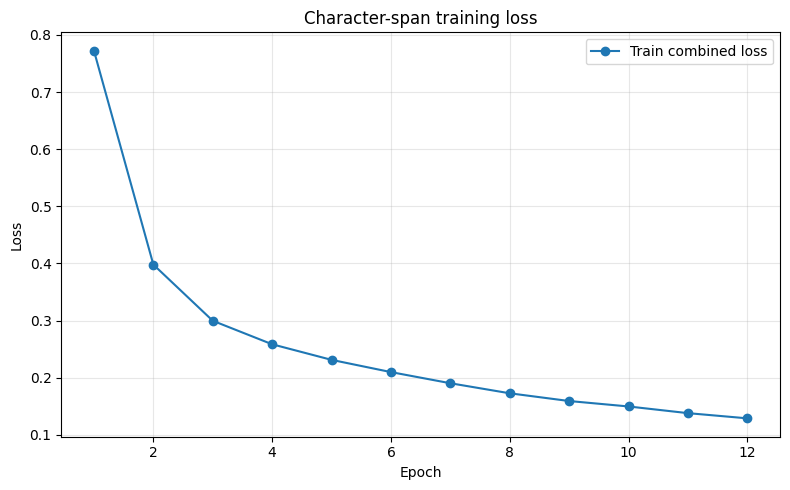

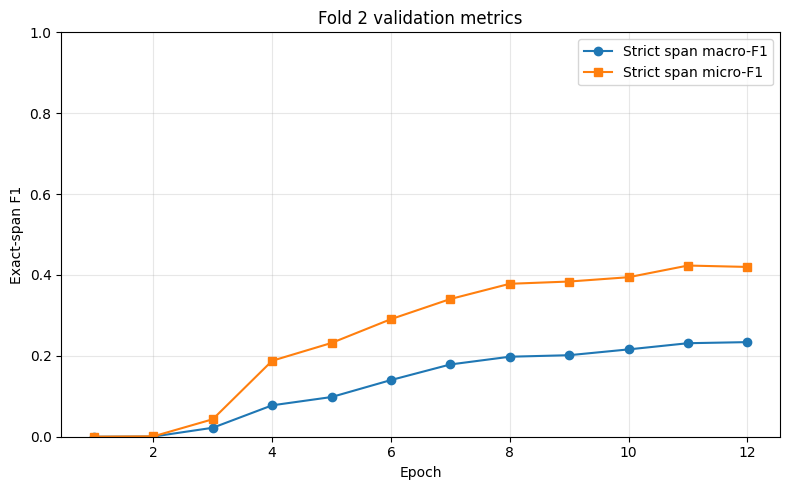

Predicting Fold 3:   0%|          | 0/35 [00:00<?, ?it/s]

Character-span Phase 2 v3 complete.
Best validation macro-F1: 0.2339326196801289
Selected confidence threshold: 0.15
Best checkpoint: /kaggle/working/phase2_lner_character_span/best_lner_character_span.pt
Prediction JSON: /kaggle/working/phase2_lner_character_span/prediction.json
Submission ZIP: /kaggle/working/phase2_lner_character_span/submission.zip
Loss plot: /kaggle/working/phase2_lner_character_span/span_loss_curve.png
F1 plot: /kaggle/working/phase2_lner_character_span/strict_entity_f1_curve.png
Sample prediction: ('1128835', [[70, 98, 'CASENO'], [99, 136, 'CASENO'], [163, 168, 'DATE'], [195, 205, 'JUDGE'], [258, 286, 'CASENO'], [287, 324, 'CASENO'], [499, 516, 'CASENO'], [521, 531, 'DATE'], [535, 563, 'CASENO'], [564, 601, 'CASENO'], [644, 647, 'CASENO'], [887, 901, 'DATE'], [917, 927, 'COURT'], [951, 988, 'CASENO'], [1188, 1198, 'AUTH'], [1454, 1464, 'AUTH'], [1529, 1549, 'STAT'], [1598, 1609, 'DATE'], [1783, 1796, 'DATE'], [2470, 2482, 'DATE'], [2701, 2718, 'DATE'], [3111, 31

In [28]:
# -----------------------------
# Full fine-tuning: character boundary loss + candidate span classification
# -----------------------------
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.float16
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
optimizer = torch.optim.AdamW(
    [
        {"params": list(phase1_decoder.parameters()), "lr": LNER_BACKBONE_LR},
        {"params": list(span_head.parameters()), "lr": LNER_HEAD_LR},
    ],
    weight_decay=LNER_WEIGHT_DECAY,
    betas=(0.9, 0.95),
    eps=1e-8,
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=1, min_lr=1e-7
)


def boundary_loss_fn(logits, targets, core_mask):
    """Masked, positive-weighted BCE on character positions in the window core."""
    mask = torch.as_tensor(core_mask, dtype=torch.bool, device=logits.device)
    if not bool(mask.any()):
        return logits.float().sum() * 0.0
    selected_logits = logits[mask].float()
    selected_targets = targets[mask].float()
    pos_weight = torch.full((NUM_ENTITY_LABELS,), BOUNDARY_POS_WEIGHT_VALUE,
                            dtype=torch.float32, device=logits.device)
    return F.binary_cross_entropy_with_logits(selected_logits, selected_targets,
                                               pos_weight=pos_weight, reduction="mean")


def _forward_span_window(row, training=False):
    ids = torch.as_tensor(row["input_ids"], dtype=torch.long, device=DEVICE).unsqueeze(0)
    attention_mask = torch.ones_like(ids)
    with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        token_hidden = decoder_hidden_states(phase1_decoder, ids, attention_mask)[0]
        aligned_hidden = align_token_hidden_to_chars(token_hidden, row["offsets"], row["text"])
        char_features = span_head.encode_char_features(aligned_hidden, row["text"])
        start_logits, end_logits = span_head.boundary_logits(char_features)
    return char_features, start_logits, end_logits


# Estimate conservative per-label span caps from Fold 1 only (never from Fold 2/Fold 3).
# This cuts off pathological hundreds-of-characters predictions while preserving spans up to
# the 99th percentile of that label's training lengths. Review the printed table before submission.
_LABEL_TRAIN_LENGTHS = {
    label: [int(ent["end"]) - int(ent["start"])
            for ents in fold1_gold.values() for ent in ents if str(ent["label"]) == label]
    for label in ENTITY_LABELS
}
MAX_SPAN_CHARS_BY_LABEL = {}
for _label, _lengths in _LABEL_TRAIN_LENGTHS.items():
    if _lengths:
        _cap = int(np.quantile(np.asarray(_lengths, dtype=np.float32), 0.99, method="higher"))
        MAX_SPAN_CHARS_BY_LABEL[_label] = min(LNER_MAX_SPAN_CHARS, max(2, _cap))
    else:
        MAX_SPAN_CHARS_BY_LABEL[_label] = LNER_MAX_SPAN_CHARS
print("Fold-1-derived maximum decoded span lengths:", MAX_SPAN_CHARS_BY_LABEL)
print("Fold-1 span-length diagnostics:", {
    label: {"n": len(vals), "p95": int(np.quantile(vals, 0.95)) if vals else None,
            "p99": int(np.quantile(vals, 0.99)) if vals else None,
            "max": max(vals) if vals else None}
    for label, vals in _LABEL_TRAIN_LENGTHS.items()
})


@torch.no_grad()
def generate_span_candidates(start_logits, end_logits):
    """Return (start, end_exclusive, label_index) proposals, preserving boundary-label identity."""
    n_chars = int(start_logits.shape[0])
    if n_chars == 0:
        return []
    start_probs = torch.sigmoid(start_logits.float())
    end_probs = torch.sigmoid(end_logits.float())
    candidates = set()
    starts = list(range(0, n_chars, SPAN_DECODE_CHUNK_STRIDE))
    for chunk_start in starts:
        chunk_end = min(n_chars, chunk_start + SPAN_DECODE_CHUNK_CHARS)
        if chunk_end - chunk_start < SPAN_DECODE_CHUNK_CHARS and chunk_start > 0:
            chunk_start = max(0, n_chars - SPAN_DECODE_CHUNK_CHARS)
            chunk_end = n_chars
        for label_i, label in enumerate(ENTITY_LABELS):
            local_start_probs = start_probs[chunk_start:chunk_end, label_i]
            local_end_probs = end_probs[chunk_start:chunk_end, label_i]
            k = min(TOP_BOUNDARIES_PER_LABEL, int(local_start_probs.numel()))
            if k == 0:
                continue
            s_idx = (torch.topk(local_start_probs, k=k).indices + chunk_start).detach().cpu().tolist()
            e_idx = (torch.topk(local_end_probs, k=k).indices + chunk_start).detach().cpu().tolist()
            max_label_len = MAX_SPAN_CHARS_BY_LABEL[label]
            for s in s_idx:
                for end_char in e_idx:
                    if end_char < s:
                        continue
                    length = end_char - s + 1
                    if 1 <= length <= max_label_len:
                        candidates.add((int(s), int(end_char + 1), int(label_i)))
    return sorted(candidates)


@torch.no_grad()
def score_span_candidates(char_features, start_logits, end_logits, return_candidate_pairs=False, head=None):
    """Score label-preserving proposals; combine boundary confidence with span-classifier confidence."""
    head = head or span_head
    proposals = generate_span_candidates(start_logits, end_logits)
    if not proposals:
        return ([], []) if return_candidate_pairs else []

    # Reuse span-classifier results when the same (start, end) pair is proposed for multiple labels.
    unique_pairs = sorted({(s, e) for s, e, _label_i in proposals})
    pair_index = {pair: i for i, pair in enumerate(unique_pairs)}
    prob_blocks = []
    with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        for offset in range(0, len(unique_pairs), 2048):
            block = unique_pairs[offset:offset + 2048]
            logits = head.span_logits(char_features, block).float()
            prob_blocks.append(torch.softmax(logits, dim=-1))
    probs = torch.cat(prob_blocks, dim=0)
    start_probs = torch.sigmoid(start_logits.float())
    end_probs = torch.sigmoid(end_logits.float())

    scored = []
    for s, e, label_i in proposals:
        pi = pair_index[(s, e)]
        label_prob = probs[pi, label_i + 1]
        none_prob = probs[pi, 0]
        # The same label must be supported by both boundary heads and the span classifier.
        if float(label_prob.item()) <= float(none_prob.item()):
            continue
        boundary_start = start_probs[s, label_i].clamp_min(1e-8)
        boundary_end = end_probs[e - 1, label_i].clamp_min(1e-8)
        confidence = (boundary_start * boundary_end * label_prob.clamp_min(1e-8)).pow(1.0 / 3.0)
        scored.append((int(s), int(e), ENTITY_LABELS[label_i], float(confidence.item())))

    # Candidate recall now means the exact start + end + correct label was proposed.
    labeled_candidates = [(int(s), int(e), ENTITY_LABELS[int(label_i)]) for s, e, label_i in proposals]
    return (scored, labeled_candidates) if return_candidate_pairs else scored


@torch.no_grad()
def predict_document_scored_spans(text, decoder=None, head=None, batch_window_size=4, return_candidate_pairs=False):
    """Merge contextual states from overlapping token windows into document character space."""
    decoder = decoder or phase1_decoder
    head = head or span_head
    token_ids, offsets = encode_with_character_offsets(tokenizer, text)
    if not token_ids or not text:
        return ([], []) if return_candidate_pairs else []
    starts = make_window_starts(len(token_ids))
    char_hidden_sum = torch.zeros((len(text), hidden_size), dtype=torch.float32, device=DEVICE)
    char_counts = torch.zeros((len(text), 1), dtype=torch.float32, device=DEVICE)
    decoder.eval(); head.eval()

    for batch_start in range(0, len(starts), batch_window_size):
        token_starts = starts[batch_start:batch_start + batch_window_size]
        rows = []
        for ts in token_starts:
            te = min(ts + LNER_MAX_LEN, len(token_ids))
            oo = offsets[ts:te]
            cs = min(s for s, e in oo)
            ce = max(e for s, e in oo)
            local_offsets = [(s - cs, e - cs) for s, e in oo]
            rows.append((ts, te, cs, ce, local_offsets, text[cs:ce]))
        max_t = max(te - ts for ts, te, *_ in rows)
        batch_ids = torch.full((len(rows), max_t), PAD_ID, dtype=torch.long, device=DEVICE)
        batch_mask = torch.zeros((len(rows), max_t), dtype=torch.long, device=DEVICE)
        for ri, (ts, te, *_rest) in enumerate(rows):
            length = te - ts
            batch_ids[ri, :length] = torch.as_tensor(token_ids[ts:te], dtype=torch.long, device=DEVICE)
            batch_mask[ri, :length] = 1
        with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
            token_hidden_batch = decoder_hidden_states(decoder, batch_ids, batch_mask)
        for ri, (ts, te, cs, ce, local_offsets, slice_text) in enumerate(rows):
            aligned = align_token_hidden_to_chars(token_hidden_batch[ri, :te-ts], local_offsets, slice_text).float()
            char_hidden_sum[cs:ce] += aligned
            char_counts[cs:ce] += 1.0
    aligned_full = char_hidden_sum / char_counts.clamp_min(1.0)
    with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
        char_features = head.encode_char_features(aligned_full, text)
        start_logits, end_logits = head.boundary_logits(char_features)
    return score_span_candidates(char_features, start_logits, end_logits,
                                 return_candidate_pairs=return_candidate_pairs, head=head)


def decode_scored_spans(scored, threshold=0.35):
    """Threshold candidates and greedily keep the highest-confidence non-overlapping spans."""
    candidates = [x for x in scored if x[3] >= threshold]
    candidates.sort(key=lambda x: (-x[3], x[0], x[1], x[2]))
    accepted = []
    for s, e, label, confidence in candidates:
        if not any(max(s, a) < min(e, b) for a, b, _, _ in accepted):
            accepted.append((s, e, label, confidence))
    accepted.sort(key=lambda x: (x[0], x[1], x[2]))
    return [(int(s), int(e), str(label)) for s, e, label, _ in accepted]


def strict_entity_metrics(gold_documents, pred_documents, label_names):
    gold, pred = set(), set()
    for doc_id, entities in gold_documents.items():
        for ent in entities:
            gold.add((str(doc_id), int(ent["start"]), int(ent["end"]), str(ent["label"])))
    for doc_id, spans in pred_documents.items():
        for start, end, label in spans:
            pred.add((str(doc_id), int(start), int(end), str(label)))
    tp, fp, fn = len(gold & pred), len(pred - gold), len(gold - pred)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    micro_f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    per_label = {}
    for label in label_names:
        g = {x for x in gold if x[3] == label}
        p = {x for x in pred if x[3] == label}
        ltp, lfp, lfn = len(g & p), len(p - g), len(g - p)
        lp = ltp / (ltp + lfp) if ltp + lfp else 0.0
        lr = ltp / (ltp + lfn) if ltp + lfn else 0.0
        lf = 2 * lp * lr / (lp + lr) if lp + lr else 0.0
        per_label[label] = {"precision": lp, "recall": lr, "f1": lf, "tp": ltp, "fp": lfp, "fn": lfn}
    return {"precision": precision, "recall": recall, "micro_f1": micro_f1,
            "macro_f1": sum(v["f1"] for v in per_label.values()) / max(1, len(per_label)),
            "tp": tp, "fp": fp, "fn": fn, "per_label": per_label}


@torch.no_grad()
def evaluate_fold_at_threshold(documents, gold_by_doc, threshold, scored_by_doc=None, split_name="validation"):
    if scored_by_doc is None:
        scored_by_doc = {
            str(doc_id): predict_document_scored_spans(text)
            for doc_id, text in tqdm(documents.items(), desc=f"Scoring {split_name}")
        }
    predictions = {str(doc_id): decode_scored_spans(scored_by_doc.get(str(doc_id), []), threshold)
                   for doc_id in documents}
    return strict_entity_metrics(gold_by_doc, predictions, ENTITY_LABELS), predictions


@torch.no_grad()
def score_validation_documents():
    phase1_decoder.eval(); span_head.eval()
    scored_by_doc = {}
    candidate_pairs_by_doc = {}
    for doc_id, text in tqdm(fold2_docs.items(), desc="Scoring Fold 2 validation"):
        scored, pairs = predict_document_scored_spans(text, return_candidate_pairs=True)
        scored_by_doc[str(doc_id)] = scored
        candidate_pairs_by_doc[str(doc_id)] = set(pairs)

    # Candidate recall is measured before span classification, confidence thresholding,
    # or overlap suppression. It distinguishes candidate-generation failures from
    # classification/decoding failures.
    total = 0
    covered = 0
    by_label = {label: [0, 0] for label in ENTITY_LABELS}
    for doc_id, entities in fold2_gold.items():
        pair_set = candidate_pairs_by_doc.get(str(doc_id), set())
        for ent in entities:
            pair = (int(ent["start"]), int(ent["end"]), str(ent["label"]))
            label = str(ent["label"])
            total += 1
            by_label[label][1] += 1
            if pair in pair_set:
                covered += 1
                by_label[label][0] += 1
    print(f"Fold 2 exact label-aware candidate recall: {covered}/{total} = {covered / max(1, total):.1%}")
    print("Exact candidate recall by label:", {
        label: f"{hit}/{count} ({hit / max(1, count):.1%})"
        for label, (hit, count) in by_label.items()
    })
    return scored_by_doc


PHASE2_OUT_DIR = Path("/kaggle/working/phase2_lner_character_span")
PHASE2_OUT_DIR.mkdir(parents=True, exist_ok=True)
BEST_CHECKPOINT_PATH = PHASE2_OUT_DIR / "best_lner_character_span.pt"
history = []
best_macro_f1 = -1.0
best_threshold = 0.35
epochs_without_improvement = 0
optimizer_steps = 0

for epoch in range(1, LNER_EPOCHS + 1):
    phase1_decoder.train(); span_head.train()
    optimizer.zero_grad(set_to_none=True)
    batch_losses = []
    pbar = tqdm(enumerate(train_windows), total=len(train_windows),
                desc=f"Character-span fine-tuning epoch {epoch}/{LNER_EPOCHS}")
    for batch_index, row in pbar:
        try:
            with torch.autocast(device_type=DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                char_features, start_logits, end_logits = _forward_span_window(row, training=True)
                start_targets = _tensor_targets(row, "start_targets")
                end_targets = _tensor_targets(row, "end_targets")
                core_mask = row["core_mask"]
                loss_start = boundary_loss_fn(start_logits, start_targets, core_mask)
                loss_end = boundary_loss_fn(end_logits, end_targets, core_mask)
                candidates, candidate_targets = sample_training_candidates(row, start_logits.detach(), end_logits.detach())
                span_logits = span_head.span_logits(char_features, candidates).float()
                loss_span = F.cross_entropy(span_logits, candidate_targets, weight=SPAN_CLASS_WEIGHTS)
                loss = 0.5 * (loss_start + loss_end) + loss_span

            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss in epoch {epoch}: {float(loss.detach().cpu())}")
            scaler.scale(loss / LNER_GRAD_ACCUM_STEPS).backward()
            batch_losses.append(float(loss.detach().cpu()))
            accumulation_boundary = ((batch_index + 1) % LNER_GRAD_ACCUM_STEPS == 0
                                     or (batch_index + 1) == len(train_windows))
            if accumulation_boundary:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(trainable_parameters, max_norm=1.0)
                scaler.step(optimizer); scaler.update()
                optimizer.zero_grad(set_to_none=True)
                optimizer_steps += 1
            pbar.set_postfix(loss=f"{batch_losses[-1]:.4f}", steps=optimizer_steps)
        except RuntimeError as exc:
            if "out of memory" in str(exc).lower() and DEVICE.type == "cuda":
                optimizer.zero_grad(set_to_none=True)
                torch.cuda.empty_cache()
                raise RuntimeError(
                    "CUDA OOM during span fine-tuning. Reduce LNER_MAX_LEN to 512 and/or "
                    "TOP_BOUNDARIES_PER_LABEL to 24, then restart the notebook kernel and rerun."
                ) from exc
            raise

    train_loss = sum(batch_losses) / max(1, len(batch_losses))
    scored_val = score_validation_documents()
    candidates_by_threshold = []
    for threshold in SPAN_CONFIDENCE_THRESHOLDS:
        metrics, _preds = evaluate_fold_at_threshold(
            fold2_docs, fold2_gold, threshold, scored_by_doc=scored_val, split_name="Fold 2"
        )
        candidates_by_threshold.append((metrics["macro_f1"], threshold, metrics))
    val_macro_f1, selected_threshold, val_metrics = max(candidates_by_threshold, key=lambda x: x[0])
    scheduler.step(val_macro_f1)
    row = {
        "epoch": epoch,
        "train_loss": train_loss,
        "selected_threshold": selected_threshold,
        "precision": val_metrics["precision"],
        "recall": val_metrics["recall"],
        "micro_f1": val_metrics["micro_f1"],
        "macro_f1": val_metrics["macro_f1"],
        "tp": val_metrics["tp"], "fp": val_metrics["fp"], "fn": val_metrics["fn"],
        "per_label": val_metrics["per_label"],
        "learning_rates": [group["lr"] for group in optimizer.param_groups],
    }
    history.append(row)
    print(json.dumps(row, indent=2))

    if val_macro_f1 > best_macro_f1 + 1e-6:
        best_macro_f1 = val_macro_f1
        best_threshold = selected_threshold
        epochs_without_improvement = 0
        torch.save({
            "decoder_state_dict": phase1_decoder.state_dict(),
            "span_head_state_dict": span_head.state_dict(),
            "entity_labels": ENTITY_LABELS,
            "best_macro_f1": best_macro_f1,
            "best_threshold": best_threshold,
            "max_len": LNER_MAX_LEN,
            "window_stride": LNER_WINDOW_STRIDE,
            "max_span_chars": LNER_MAX_SPAN_CHARS,
            "top_boundaries_per_label": TOP_BOUNDARIES_PER_LABEL,
            "max_span_chars_by_label": MAX_SPAN_CHARS_BY_LABEL,
            "candidate_scoring": "label-aware boundary + span composite",
            "tokenizer_vocab_size": tokenizer.get_vocab_size(),
            "history": history,
            "model_config": {"vocab_size": VOCAB_SIZE, "n_embd": N_EMBD, "n_layer": N_LAYER,
                             "n_head": N_HEAD, "n_kv_head": N_KV_HEAD,
                             "context_length": MODEL_CONTEXT_LENGTH},
        }, BEST_CHECKPOINT_PATH)
        print(f"Saved best character-span checkpoint: {BEST_CHECKPOINT_PATH}")
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= LNER_PATIENCE:
            print(f"Early stopping after {epoch} epochs; best macro-F1={best_macro_f1:.4f}")
            break

with open(PHASE2_OUT_DIR / "training_history.json", "w", encoding="utf-8") as f:
    json.dump(history, f, indent=2)

import matplotlib.pyplot as plt
_epochs = [item["epoch"] for item in history]
plt.figure(figsize=(8, 5))
plt.plot(_epochs, [item["train_loss"] for item in history], marker="o", label="Train combined loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Character-span training loss")
plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
LOSS_PLOT_PATH = PHASE2_OUT_DIR / "span_loss_curve.png"
plt.savefig(LOSS_PLOT_PATH, dpi=160); plt.show()

plt.figure(figsize=(8, 5))
plt.plot(_epochs, [item["macro_f1"] for item in history], marker="o", label="Strict span macro-F1")
plt.plot(_epochs, [item["micro_f1"] for item in history], marker="s", label="Strict span micro-F1")
plt.xlabel("Epoch"); plt.ylabel("Exact-span F1"); plt.title("Fold 2 validation metrics")
plt.ylim(0.0, 1.0); plt.grid(True, alpha=0.3); plt.legend(); plt.tight_layout()
F1_PLOT_PATH = PHASE2_OUT_DIR / "strict_entity_f1_curve.png"
plt.savefig(F1_PLOT_PATH, dpi=160); plt.show()

# Reload the best checkpoint, then predict Fold 3 without training/tuning on its labels.
checkpoint = torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE, weights_only=False)
phase1_decoder.load_state_dict(checkpoint["decoder_state_dict"])
span_head.load_state_dict(checkpoint["span_head_state_dict"])
span_head.eval(); phase1_decoder.eval()
best_threshold = float(checkpoint.get("best_threshold", 0.35))

fold3_predictions = {}
for doc_id, text in tqdm(test_docs.items(), desc="Predicting Fold 3"):
    scored = predict_document_scored_spans(text, phase1_decoder, span_head)
    spans = decode_scored_spans(scored, best_threshold)
    fold3_predictions[str(doc_id)] = [[int(start), int(end), label] for start, end, label in spans]

prediction_path = PHASE2_OUT_DIR / "prediction.json"
with open(prediction_path, "w", encoding="utf-8") as f:
    json.dump(fold3_predictions, f, ensure_ascii=False, indent=2)
submission_zip_path = PHASE2_OUT_DIR / "submission.zip"
with zipfile.ZipFile(submission_zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(prediction_path, arcname="prediction.json")
assert set(fold3_predictions.keys()) == set(test_docs.keys()), "Fold 3 IDs are missing or extra."
with zipfile.ZipFile(submission_zip_path, "r") as zf:
    assert zf.namelist() == ["prediction.json"], f"Unexpected ZIP contents: {zf.namelist()}"
print("Character-span Phase 2 v3 complete.")
print("Best validation macro-F1:", best_macro_f1)
print("Selected confidence threshold:", best_threshold)
print("Best checkpoint:", BEST_CHECKPOINT_PATH)
print("Prediction JSON:", prediction_path)
print("Submission ZIP:", submission_zip_path)
print("Loss plot:", LOSS_PLOT_PATH)
print("F1 plot:", F1_PLOT_PATH)
print("Sample prediction:", next(iter(fold3_predictions.items()), None))


## Output files (v3)

The notebook writes these files under `/kaggle/working/phase2_lner_character_span/`:

- `best_lner_character_span.pt` — best custom decoder + character/span head, selected by Fold 2 strict macro-F1
- `training_history.json` — epoch metrics, threshold and per-label scores
- `span_loss_curve.png` — training loss
- `strict_entity_f1_curve.png` — Fold 2 strict macro/micro F1
- `prediction.json` — Fold 3 predictions as `[start_character, end_character, label]`
- `submission.zip` — ZIP containing `prediction.json` at its root

### Runtime notes

- This performs full fine-tuning of the custom Phase 1 decoder; no unrelated pretrained LLM is substituted.
- The character projection supports character boundaries inside BPE tokens.
- v3 preserves the label attached to each start/end proposal, combines label-specific boundary and span confidence, mines negatives from model-generated candidates, and applies Fold-1-derived label-specific span-length caps.
- Candidate recall is exact and label-aware (start, end, and gold label), unlike v2's union-of-labels pair recall.
- Training is memory-conservative (one window per forward pass and gradient accumulation). If CUDA OOM occurs, reduce `LNER_MAX_LEN` to `512` and `TOP_BOUNDARIES_PER_LABEL` to `24`, restart the kernel and run from the beginning.
- Per epoch, Fold 2 predictions are computed once and reused for the global confidence-threshold sweep. Fold 3 is not used for model selection.
- This notebook has not been run end-to-end against your Kaggle GPU/dataset in this environment; validate the printed sample predictions, runtime and official submission schema before final submission.